# Chicago Incidents of Crime

Datasource:\
https://catalog.data.gov/dataset/crimes-2001-to-present?from_hint=eyJzb3J0IjoicG9wdWxhcml0eSJ9
<br>
https://data.cityofchicago.org/Public-Safety/Crimes-2001-to-Present/ijzp-q8t2/about_data

This dataset reflects reported incidents of crime (with the exception of murders where data exists for each victim) that occurred in the City of Chicago from 2020 to present, minus the most recent seven days. Data is extracted from the Chicago Police Department's CLEAR (Citizen Law Enforcement Analysis and Reporting) system. In order to protect the privacy of crime victims, addresses are shown at the block level only and specific locations are not identified.

### Variables

| Variable | Descriptions |
| --- | --- |
| `ID` | Unique identifier for the record. |
| `Case Number` | The Chicago Police Department RD Number (Records Division Number), which is unique to the incident. | 
| `Date` | Date when the incident occurred. this is sometimes a best estimate. | 
| `Block` | The partially redacted address where the incident occurred, placing it on the same block as the actual address. | 
| `IUCR` | The Illinois Uniform Crime Reporting code. This is directly linked to the Primary Type and Description. | 
| `Primary Type` | The primary description of the IUCR code. | 
| `Description` | The secondary description of the IUCR code, a subcategory of the primary description. | 
| `Location Description` | Description of the location where the incident occurred. | 
| `Arrest` | Indicates whether an arrest was made. | 
| `Domestic` | Indicates whether the incident was domestic-related as defined by the Illinois Domestic Violence Act. | 
| `Beat` | Indicates the beat where the incident occurred. A beat is the smallest police geographic area – each beat has a dedicated police beat car. Three to five beats make up a police sector, and three sectors make up a police district. The Chicago Police Department has 22 police districts. | 
| `District` | Indicates the police district where the incident occurred. | 
| `Ward` | The ward (City Council district) where the incident occurred. | 
| `Community Area` | Indicates the community area where the incident occurred. | 
| `FBI Code` | Indicates the crime classification as outlined in the FBI's National Incident-Based Reporting System (NIBRS). | 
| `X Coordinate` | The x coordinate of the location where the incident occurred in State Plane Illinois East NAD 1983 projection. This location is shifted from the actual location for partial redaction but falls on the same block. | 
| `Y Coordinate` | The y coordinate of the location where the incident occurred in State Plane Illinois East NAD 1983 projection. This location is shifted from the actual location for partial redaction but falls on the same block. | 
| `Year` | Year the incident occurred. | 
| `Updated On` | Date and time the record was last updated. | 
| `Latitude` | The latitude of the location where the incident occurred. This location is shifted from the actual location for partial redaction but falls on the same block. | 
| `Longitude` | The longitude of the location where the incident occurred. This location is shifted from the actual location for partial redaction but falls on the same block. | 
| `Location` | The location where the incident occurred in a format that allows for creation of maps and other geographic operations on this data portal. This location is shifted from the actual location for partial redaction but falls on the same block. | 

### Import Dataset & Library

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

In [2]:
pd.set_option('display.max_colwidth', None)
pd.set_option('display.max_columns', None)
from IPython.display import display_html

In [3]:
path = ''

In [4]:
df_raw = pd.read_csv(path + '2020_Chicago Crimes.csv', low_memory=False)

### Explore Data

In [5]:
df_raw.head()

,ID,Case Number,Date,Block,IUCR,Primary Type,Description,Location Description,Arrest,Domestic,Beat,District,Ward,Community Area,FBI Code,X Coordinate,Y Coordinate,Year,Updated On,Latitude,Longitude,Location
0,14349190,JK439665,10/05/2026 12:00:00 AM,031XX E 79TH ST,0340,ROBBERY,ATTEMPT STRONG ARM - NO WEAPON,CTA BUS,False,False,422.0,4.0,7.0,46.0,03,1198323.0,1853184.0,2026.0,10/12/2026 03:48:25 PM,41.751968,-87.548800,"(41.751967657, -87.548800123)"
1,14348712,JK438996,10/05/2026 12:00:00 AM,020XX W 52ND ST,1320,CRIMINAL DAMAGE,TO VEHICLE,STREET,False,False,932.0,9.0,16.0,61.0,14,1163724.0,1870010.0,2026.0,10/12/2026 03:48:25 PM,41.798936,-87.675118,"(41.798936259, -87.675117522)"
2,14349617,JK440087,10/05/2026 12:00:00 AM,040XX W ADAMS ST,1130,DECEPTIVE PRACTICE,FRAUD OR CONFIDENCE GAME,SMALL RETAIL STORE,False,False,1115.0,11.0,28.0,26.0,11,1149594.0,1898707.0,2026.0,10/12/2026 03:48:25 PM,41.877970,-87.726192,"(41.877969824, -87.72619208)"
3,14349352,JK439833,10/05/2026 12:00:00 AM,007XX S CICERO AVE,1310,CRIMINAL DAMAGE,TO PROPERTY,CTA TRAIN,False,False,1533.0,15.0,29.0,25.0,14,1144508.0,1896325.0,2026.0,10/12/2026 03:48:25 PM,41.871531,-87.744927,"(41.871530533, -87.744926805)"
4,14348648,JK438986,10/05/2026 12:00:00 AM,012XX W AUGUSTA BLVD,0910,MOTOR VEHICLE THEFT,AUTOMOBILE,STREET,False,False,1213.0,12.0,27.0,24.0,07,1168290.0,1906828.0,2026.0,10/12/2026 03:48:25 PM,41.899871,-87.657310,"(41.899870981, -87.657310044)"


In [6]:
print('df Shape:' , df_raw.shape,'\n')
print('Duplicated rows: ', df_raw.duplicated(subset='Case Number').sum(),'\n')
print('Null rows: ', df_raw.isna().sum(),'\n')
print(df_raw.columns)

df Shape: (1588093, 22) 

Duplicated rows:  211 

Null rows:  ID                          0
Case Number                 5
Date                        5
Block                       5
IUCR                        5
Primary Type                5
Description                 5
Location Description     8862
Arrest                      5
Domestic                    5
Beat                        5
District                    5
Ward                       39
Community Area            141
FBI Code                    5
X Coordinate            25227
Y Coordinate            25227
Year                        5
Updated On                  5
Latitude                25227
Longitude               25227
Location                25227
dtype: int64 

Index(['ID', 'Case Number', 'Date', 'Block', 'IUCR', 'Primary Type',
       'Description', 'Location Description', 'Arrest', 'Domestic', 'Beat',
       'District', 'Ward', 'Community Area', 'FBI Code', 'X Coordinate',
       'Y Coordinate', 'Year', 'Updated On', 

In [7]:
# Remove duplicate records, and unused column

df = df_raw.copy().drop(columns=['ID', 
                                 'X Coordinate', 
                                 'Y Coordinate', 
                                 'Updated On',
                                 'Location'])

df = df.drop_duplicates(subset='Case Number')


In [8]:
#Unique Values from Dataset
Unique_Dict = {
    'columns' : [],
    'unique_count' : [],
    'unique' : [],
    'dtype' : []
}

for idx in range( len(df.columns) ) :
    Unique_Dict['columns'].append(df.columns[idx])
    Unique_Dict['unique_count'].append(df[df.columns[idx]].nunique())
    if (df[df.columns[idx]].nunique()) < 35:
        Unique_Dict['unique'].append(df[df.columns[idx]].unique())
    else:
        Unique_Dict['unique'].append('More than 20')
    Unique_Dict['dtype'].append(df.dtypes.iloc[idx])

pd.DataFrame(Unique_Dict)

,columns,unique_count,unique,dtype
0,Case Number,1587881,More than 20,str
1,Date,789004,More than 20,str
2,Block,38360,More than 20,str
3,IUCR,371,More than 20,str
4,Primary Type,33,"[ROBBERY, CRIMINAL DAMAGE, DECEPTIVE PRACTICE, MOTOR VEHICLE THEFT, ASSAULT, BATTERY, ARSON, THEFT, BURGLARY, OTHER OFFENSE, WEAPONS VIOLATION, PUBLIC PEACE VIOLATION, INTERFERENCE WITH PUBLIC OFFICER, NARCOTICS, CRIMINAL SEXUAL ASSAULT, CONCEALED CARRY LICENSE VIOLATION, CRIMINAL TRESPASS, OFFENSE INVOLVING CHILDREN, STALKING, SEX OFFENSE, INTIMIDATION, HOMICIDE, KIDNAPPING, LIQUOR LAW VIOLATION, OBSCENITY, OTHER NARCOTIC VIOLATION, NON-CRIMINAL, GAMBLING, PROSTITUTION, PUBLIC INDECENCY, HUMAN TRAFFICKING, RITUALISM, CRIM SEXUAL ASSAULT, nan]",str
5,Description,473,More than 20,str
6,Location Description,182,More than 20,str
7,Arrest,2,"[False, True, nan]",object
8,Domestic,2,"[False, True, nan]",object
9,Beat,276,More than 20,float64


In [9]:
# Check NaN records
df[df['Case Number'].isna()==True]

,Case Number,Date,Block,IUCR,Primary Type,Description,Location Description,Arrest,Domestic,Beat,District,Ward,Community Area,FBI Code,Year,Latitude,Longitude
1588088,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [10]:
# Remove NaN records
df = df.dropna(subset='Case Number')

In [11]:
#Unique Values from Dataset
Unique_Dict = {
    'columns' : [],
    'unique_count' : [],
    'unique' : [],
    'dtype' : []
}

for idx in range( len(df.columns) ) :
    Unique_Dict['columns'].append(df.columns[idx])
    Unique_Dict['unique_count'].append(df[df.columns[idx]].nunique())
    if (df[df.columns[idx]].nunique()) < 35:
        Unique_Dict['unique'].append(df[df.columns[idx]].unique())
    else:
        Unique_Dict['unique'].append('More than 20')
    Unique_Dict['dtype'].append(df.dtypes.iloc[idx])

pd.DataFrame(Unique_Dict)

,columns,unique_count,unique,dtype
0,Case Number,1587881,More than 20,str
1,Date,789004,More than 20,str
2,Block,38360,More than 20,str
3,IUCR,371,More than 20,str
4,Primary Type,33,"[ROBBERY, CRIMINAL DAMAGE, DECEPTIVE PRACTICE, MOTOR VEHICLE THEFT, ASSAULT, BATTERY, ARSON, THEFT, BURGLARY, OTHER OFFENSE, WEAPONS VIOLATION, PUBLIC PEACE VIOLATION, INTERFERENCE WITH PUBLIC OFFICER, NARCOTICS, CRIMINAL SEXUAL ASSAULT, CONCEALED CARRY LICENSE VIOLATION, CRIMINAL TRESPASS, OFFENSE INVOLVING CHILDREN, STALKING, SEX OFFENSE, INTIMIDATION, HOMICIDE, KIDNAPPING, LIQUOR LAW VIOLATION, OBSCENITY, OTHER NARCOTIC VIOLATION, NON-CRIMINAL, GAMBLING, PROSTITUTION, PUBLIC INDECENCY, HUMAN TRAFFICKING, RITUALISM, CRIM SEXUAL ASSAULT]",str
5,Description,473,More than 20,str
6,Location Description,182,More than 20,str
7,Arrest,2,"[False, True]",object
8,Domestic,2,"[False, True]",object
9,Beat,276,More than 20,float64


In [12]:
df['Date'] = pd.to_datetime(df['Date'], format='mixed')
df = df.astype({'Year' : 'int'})

### Handling Missing Values

In [13]:
# Handling Missing Value: Ward & Community Area
# Extract unique values from each 'Beat'

Unique_Dict = {
    'Beat' : [],
    'Ward' : [],
    'Comm_Area' : [],
    'Nan_Val' : []
}

for idx, police_beat in enumerate(df['Beat'].unique()):
    Unique_Dict['Beat'].append(police_beat)
    Unique_Dict['Ward'].append(df[df['Beat']==police_beat]['Ward'].unique())
    Unique_Dict['Comm_Area'].append(df[df['Beat']==police_beat]['Community Area'].unique())

    if (np.isnan(df[df['Beat']==police_beat]['Ward'].unique()).sum() > 0) or (np.isnan(df[df['Beat']==police_beat]['Community Area'].unique()).sum() > 0):
        Unique_Dict['Nan_Val'].append(1)
    else:
        Unique_Dict['Nan_Val'].append(np.nan)

df_War_Comm = pd.DataFrame(Unique_Dict)

In [14]:
df_War_Comm = df_War_Comm.dropna(subset='Nan_Val').reset_index(drop=True)

In [15]:
# Find mode of Ward and Community Area, grouped by Beat

for idx in range(0, len(df_War_Comm['Beat'])):
    df_War_Comm.loc[idx, 'Mode_Ward'] = df[df['Beat']==df_War_Comm.loc[idx, 'Beat']]['Ward'].mode().item()
    df_War_Comm.loc[idx, 'Mode_Comm'] = df[df['Beat']==df_War_Comm.loc[idx, 'Beat']]['Community Area'].mode().item()

Dict_Ward = df_War_Comm.set_index('Beat')['Mode_Ward'].to_dict()
Dict_Comm = df_War_Comm.set_index('Beat')['Mode_Comm'].to_dict()

df_War_Comm

,Beat,Ward,Comm_Area,Nan_Val,Mode_Ward,Mode_Comm
0,1611.0,"[39.0, 41.0, 45.0, nan]","[10.0, 9.0, 11.0]",1.0,41.0,10.0
1,1614.0,"[41.0, 38.0, nan]","[76.0, 10.0, 17.0, nan]",1.0,41.0,76.0
2,2212.0,"[19.0, nan, 34.0]","[72.0, 75.0, nan]",1.0,19.0,75.0
3,2411.0,"[50.0, 40.0, 49.0]","[2.0, nan]",1.0,50.0,2.0
4,2422.0,"[49.0, nan]",[1.0],1.0,49.0,1.0
5,1612.0,"[41.0, nan]","[10.0, 9.0]",1.0,41.0,10.0
6,1654.0,"[41.0, nan]","[76.0, nan]",1.0,41.0,76.0


In [16]:
# Fill missing value with Mode

df['Ward'] = np.where( (df['Ward'].isna()==True) | (df['Ward']==0), 
                       df['Beat'].map(Dict_Ward), 
                       df['Ward'])

df['Community Area'] = np.where( (df['Community Area'].isna()==True) | (df['Community Area']==0), 
                       df['Beat'].map(Dict_Comm), 
                       df['Community Area'])

In [17]:
print('df Shape:' , df.shape,'\n')
print('Duplicated rows: ', df.duplicated(subset='Case Number').sum(),'\n')
print('Null rows: ', df.isna().sum(),'\n')
print(df.columns)

df Shape: (1587881, 17) 

Duplicated rows:  0 

Null rows:  Case Number                 0
Date                        0
Block                       0
IUCR                        0
Primary Type                0
Description                 0
Location Description     8857
Arrest                      0
Domestic                    0
Beat                        0
District                    0
Ward                     2132
Community Area           2132
FBI Code                    0
Year                        0
Latitude                25222
Longitude               25222
dtype: int64 

Index(['Case Number', 'Date', 'Block', 'IUCR', 'Primary Type', 'Description',
       'Location Description', 'Arrest', 'Domestic', 'Beat', 'District',
       'Ward', 'Community Area', 'FBI Code', 'Year', 'Latitude', 'Longitude'],
      dtype='str')


In [18]:
print ( df[df['Ward'].isna()==True]['Beat'].unique() )
print ( df[df['Community Area'].isna()==True]['Beat'].unique() )

[6100.]
[6100.]


Source: https://data.cityofchicago.org/stories/s/Crimes-With-No-Known-Location-9-8-2026/g94p-vvmz/ \
To avoid confusion, there have long been a small number of records (on the order of one percent, overall) that have no Latitude/Longitude (and therefore X Coordinate, Y Coordinate, and Location) values but do have street addresses. The currently missing records to be added shortly have no known street addresses and will be assigned to Beat 6100 (not a beat that exists in the physical world).

In [19]:
df = df.dropna(subset='Community Area').reset_index(drop=True)

In [20]:
df['Date'].describe()

count                       1585749
mean     2023-07-05 05:57:34.864091
min             2020-01-23 12:31:00
25%             2021-12-10 15:00:00
50%             2023-07-24 09:00:00
75%             2025-01-31 19:30:00
max             2026-10-05 00:00:00
Name: Date, dtype: object

In [21]:
# Keep data from beginning until Sep 2026
df = df[df['Date'] < '2026-10-01']

In [22]:
# Extract Time
df['Hour'] = df['Date'].dt.hour
df['Minute'] = df['Date'].dt.minute

# Rounded hours  
df['Time'] = np.where(df['Minute']>30, (df['Date'] + pd.Timedelta(hours=1)).dt.hour, df['Hour'])

In [23]:
df = df.astype({
    'Beat' : 'int',
    'District' : 'int',
    'Ward' : 'int',
    'Year' : 'int',
})

In [24]:
#Unique Values from Dataset
Unique_Dict = {
    'columns' : [],
    'unique_count' : [],
    'unique' : [],
    'dtype' : []
}

for idx in range( len(df.columns) ) :
    Unique_Dict['columns'].append(df.columns[idx])
    Unique_Dict['unique_count'].append(df[df.columns[idx]].nunique())
    if (df[df.columns[idx]].nunique()) < 35:
        Unique_Dict['unique'].append(df[df.columns[idx]].unique())
    else:
        Unique_Dict['unique'].append('More than 20')
    Unique_Dict['dtype'].append(df.dtypes.iloc[idx])

pd.DataFrame(Unique_Dict)

,columns,unique_count,unique,dtype
0,Case Number,1583271,More than 20,str
1,Date,787180,More than 20,datetime64[us]
2,Block,38349,More than 20,str
3,IUCR,371,More than 20,str
4,Primary Type,33,"[THEFT, DECEPTIVE PRACTICE, BURGLARY, CRIMINAL DAMAGE, BATTERY, ROBBERY, ASSAULT, OTHER OFFENSE, PUBLIC PEACE VIOLATION, MOTOR VEHICLE THEFT, WEAPONS VIOLATION, SEX OFFENSE, OFFENSE INVOLVING CHILDREN, NARCOTICS, CONCEALED CARRY LICENSE VIOLATION, CRIMINAL SEXUAL ASSAULT, INTERFERENCE WITH PUBLIC OFFICER, LIQUOR LAW VIOLATION, CRIMINAL TRESPASS, HOMICIDE, STALKING, OBSCENITY, INTIMIDATION, KIDNAPPING, ARSON, OTHER NARCOTIC VIOLATION, NON-CRIMINAL, GAMBLING, PROSTITUTION, PUBLIC INDECENCY, HUMAN TRAFFICKING, RITUALISM, CRIM SEXUAL ASSAULT]",str
5,Description,473,More than 20,str
6,Location Description,182,More than 20,str
7,Arrest,2,"[False, True]",object
8,Domestic,2,"[False, True]",object
9,Beat,275,More than 20,int64


### Exploratory Data Analysis

In [25]:
Color_T = 'orangered'
Color_F = 'papayawhip'
color_pallete = {0:Color_F, 1:Color_T}

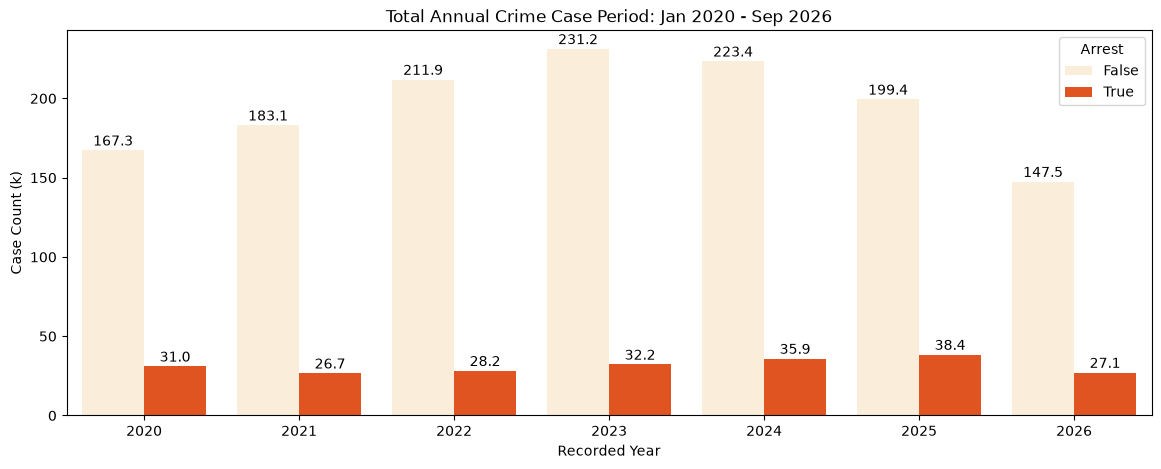

In [26]:
df_plot = df.groupby(['Arrest','Year'], as_index=False)[['Case Number']].count()
df_plot = df_plot.rename(columns={'Case Number':'Case Count (k)'}).sort_values(by='Case Count (k)', ascending=False).reset_index(drop=True)
df_plot['Case Count (k)'] = df_plot['Case Count (k)'] /1000

plt.figure(figsize=(14,5))

ax = sns.barplot(data=df_plot, x='Year', y='Case Count (k)', estimator='sum', hue='Arrest', errorbar=None, palette=color_pallete)
ax.set_title('Total Annual Crime Case Period: Jan 2020 - Sep 2026')
ax.set_xlabel('Recorded Year')

# Bar Annotation
for container in ax.containers:
  ax.bar_label(container, fmt="%.1f", label_type="edge", color='black', padding=1)

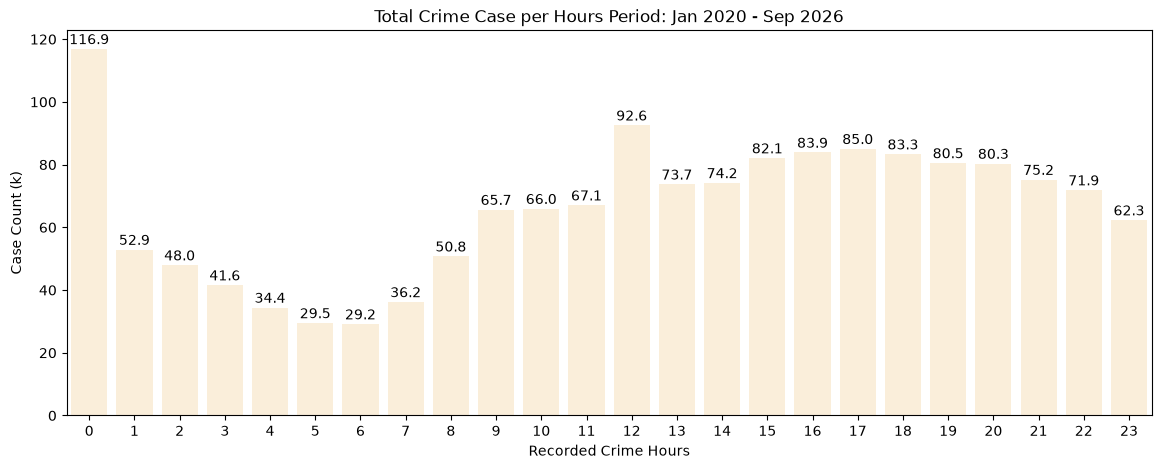

In [27]:
df_plot = df.groupby('Time', as_index=False)[['Case Number']].count()
df_plot = df_plot.rename(columns={'Case Number':'Case Count (k)'}).sort_values(by='Case Count (k)', ascending=False).reset_index(drop=True)
df_plot['Case Count (k)'] = df_plot['Case Count (k)'] /1000

plt.figure(figsize=(14,5))

ax = sns.barplot(data=df_plot, x='Time', y='Case Count (k)', estimator='sum', errorbar=None, color=Color_F)
ax.set_title('Total Crime Case per Hours Period: Jan 2020 - Sep 2026')
ax.set_xlabel('Recorded Crime Hours')

# Bar Annotation
for container in ax.containers:
  ax.bar_label(container, fmt="%.1f", label_type="edge", color='black', padding=1)

A lot of crimes happened during midnight and midday.

In [28]:
# Midnight: 23:00 - 00:59

df_Midnight = df[ (df['Date'].dt.hour>=23) | (df['Date'].dt.hour==0) ]

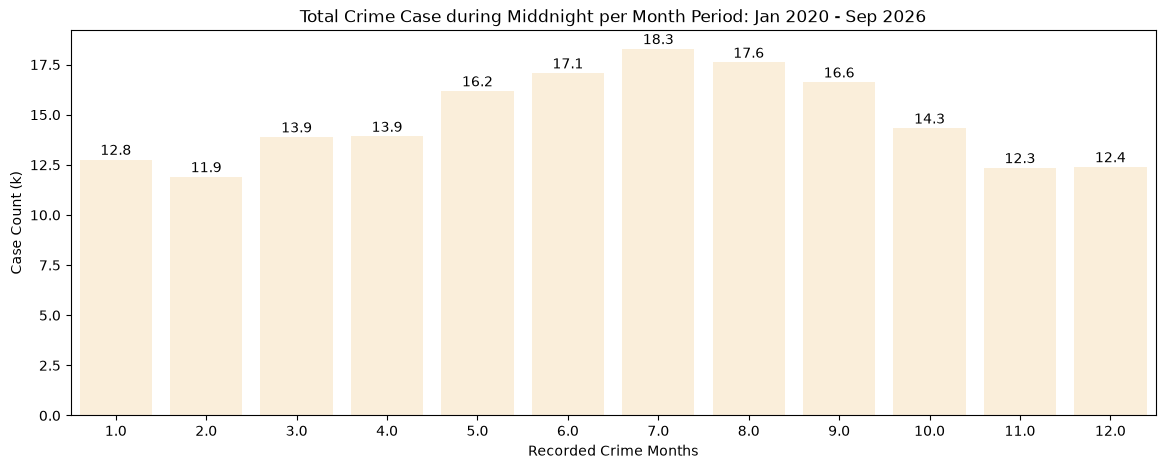

In [29]:
# Crime Case during Midnight (aggregate each months)

df_plot = df.groupby(df_Midnight['Date'].dt.month, as_index=False)[['Case Number']].count()
df_plot = df_plot.rename(columns={'Case Number':'Case Count (k)','Date':'Month'}).reset_index(drop=True)
df_plot['Case Count (k)'] = df_plot['Case Count (k)'] /1000

plt.figure(figsize=(14,5))

ax = sns.barplot(data=df_plot, x='Month', y='Case Count (k)', estimator='sum', errorbar=None, color=Color_F)
ax.set_title('Total Crime Case during Middnight per Month Period: Jan 2020 - Sep 2026')
ax.set_xlabel('Recorded Crime Months')

# Bar Annotation
for container in ax.containers:
  ax.bar_label(container, fmt="%.1f", label_type="edge", color='black', padding=1)


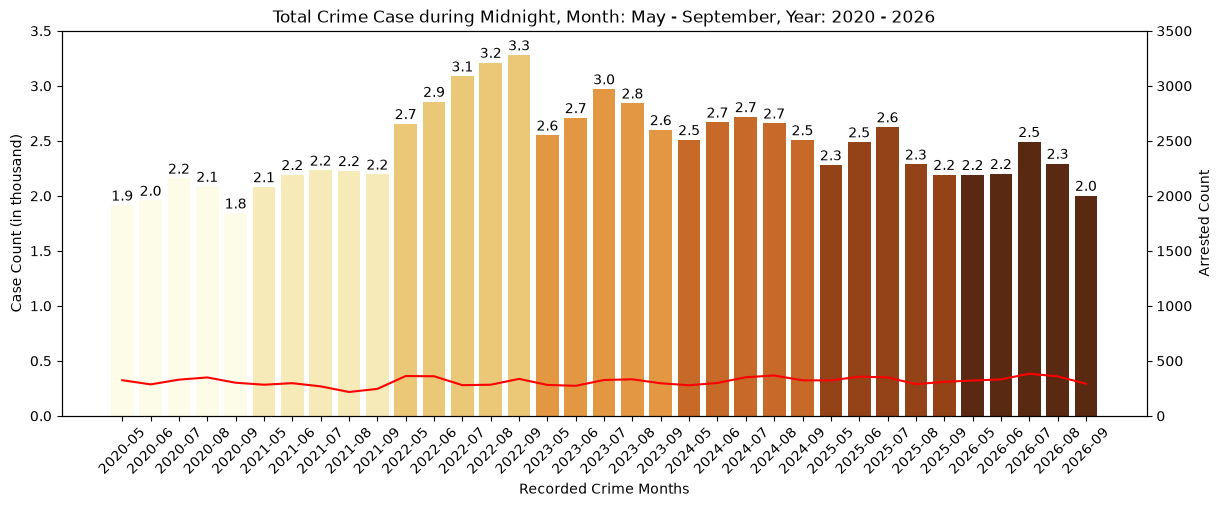

In [30]:
df_Midnight_M = df[ ((df['Date'].dt.hour>=23) | (df['Date'].dt.hour==0)) & ((df['Date'].dt.month)>=5) & ((df['Date'].dt.month)<=9) ]

df_plot = df.groupby([df_Midnight_M['Date'].dt.to_period('M').astype('str'), 'Year'], as_index=False)[['Case Number']].count()
df_plot = df_plot.rename(columns={'Case Number':'Case Count (k)','Date':'Month'}).reset_index(drop=True)
df_plot['Case Count (k)'] = df_plot['Case Count (k)'] /1000

df_Arrest_Night = df[df['Arrest']==True].groupby([df_Midnight_M['Date'].dt.to_period('M').astype('str'), 'Year'], as_index=False)[['Case Number']].count()
df_Arrest_Night = df_Arrest_Night.rename(columns={'Case Number':'Arrest Number','Date':'Month'})

fig, axes1 = plt.subplots(figsize=(14,5))

axes1 = sns.barplot(data=df_plot, x='Month', y='Case Count (k)', estimator='sum', hue='Year', errorbar=None, palette='YlOrBr', legend=False)
axes1.set_title('Total Crime Case during Midnight, Month: May - September, Year: 2020 - 2026')
axes1.set_ylabel('Case Count (in thousand)')
axes1.set_xlabel('Recorded Crime Months')
axes1.set_yticks(np.arange(0,3.51,0.5))
axes1.tick_params(axis="x", rotation=45)

axes2 = axes1.twinx()

axes2 = sns.lineplot(data=df_Arrest_Night, x='Month', y='Arrest Number', color='r')
axes2.set_ylabel('Arrested Count')
axes2.set_yticks(range(0,3501,500))

# Bar Annotation
for container in axes1.containers:
  axes1.bar_label(container, fmt="%.1f", label_type="edge", color='black', padding=1)


In [31]:
# Midday: 11:00 - 12:59

df_Midday = df[(df['Date'].dt.hour>=11) & (df['Date'].dt.hour<=12)]

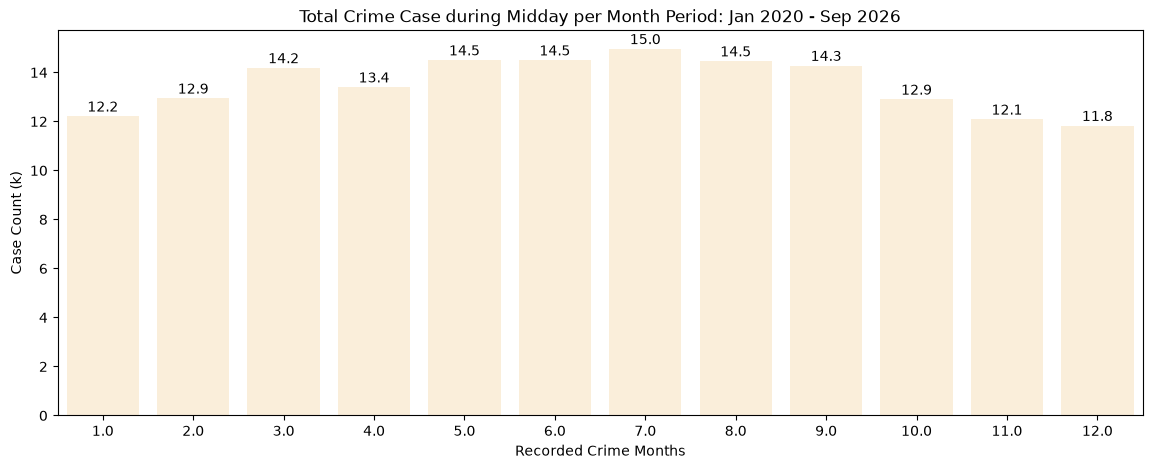

In [32]:
# Crime Case druing Midday (aggregate each months)

df_plot = df.groupby(df_Midday['Date'].dt.month, as_index=False)[['Case Number']].count()
df_plot = df_plot.rename(columns={'Case Number':'Case Count (k)','Date':'Month'}).reset_index(drop=True)
df_plot['Case Count (k)'] = df_plot['Case Count (k)'] /1000

plt.figure(figsize=(14,5))

ax = sns.barplot(data=df_plot, x='Month', y='Case Count (k)', estimator='sum', errorbar=None, color=Color_F)
ax.set_title('Total Crime Case during Midday per Month Period: Jan 2020 - Sep 2026')
ax.set_xlabel('Recorded Crime Months')

# Bar Annotation
for container in ax.containers:
  ax.bar_label(container, fmt="%.1f", label_type="edge", color='black', padding=1)


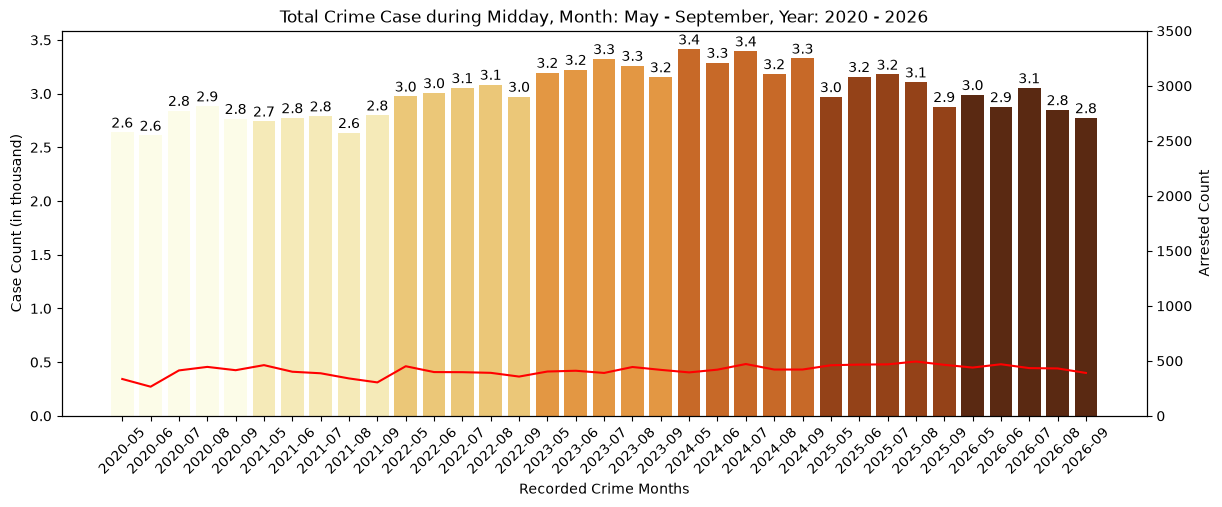

In [33]:
df_Midday_M = df[ ((df['Date'].dt.hour>=11) & (df['Date'].dt.hour<=13)) & (((df['Date'].dt.month)>=5) & ((df['Date'].dt.month)<=9)) ]

df_plot = df.groupby([df_Midday_M['Date'].dt.to_period('M').astype('str'), 'Year'], as_index=False)[['Case Number']].count()
df_plot = df_plot.rename(columns={'Case Number':'Case Count (k)','Date':'Month'}).reset_index(drop=True)
df_plot['Case Count (k)'] = df_plot['Case Count (k)'] /1000

df_Arrest_Day = df[df['Arrest']==True].groupby([df_Midday_M['Date'].dt.to_period('M').astype('str'), 'Year'], as_index=False)[['Case Number']].count()
df_Arrest_Day = df_Arrest_Day.rename(columns={'Case Number':'Arrest Number','Date':'Month'})

fig, axes1 = plt.subplots(figsize=(14,5))

axes1 = sns.barplot(data=df_plot, x='Month', y='Case Count (k)', estimator='sum', hue='Year', errorbar=None, palette='YlOrBr', legend=False)
axes1.set_title('Total Crime Case during Midday, Month: May - September, Year: 2020 - 2026')
axes1.set_ylabel('Case Count (in thousand)')
axes1.set_xlabel('Recorded Crime Months')
axes1.set_yticks(np.arange(0,3.51,0.5))
axes1.tick_params(axis="x", rotation=45)

axes2 = axes1.twinx()

axes2 = sns.lineplot(data=df_Arrest_Day, x='Month', y='Arrest Number', color='r')
axes2.set_ylabel('Arrested Count')
axes2.set_yticks(range(0,3501,500))

# Bar Annotation
for container in axes1.containers:
  axes1.bar_label(container, fmt="%.1f", label_type="edge", color='black', padding=1)


Compared to midnight time, total crime remains high during Midday.

In [34]:
# Estimation of Chicago Population from U.S. Census Bureau 
# Source: https://www.census.gov/data/tables/time-series/demo/popest/2020s-total-cities-and-towns.html

Chicago_Pop = {
    'Year' : [2020, 2021, 2022, 2023, 2024, 2025, 2026],
    'Population' : [2741640, 2705934, 2680609, 2698758, 2726332, 2731585, 2731585]
}

df_Pop = pd.DataFrame (Chicago_Pop).set_index('Year')

In [35]:
from scipy.stats import chi2_contingency

In [36]:
# Compare each month recorded crime across years
# Use Chi-Squared if there's association between crime rate for each months

for year in df_Midday['Year'].unique():

    print(f'\nMonthly Observation Year: {year}')

    df_Midday_Y = df_Midday[df_Midday['Year']==year][['Date','Year','Case Number']]
    
    pivot_year = df_Midday_Y.groupby(df_Midday_Y['Date'].dt.month.astype('int'))[['Case Number']].count()
    pivot_year['Population'] = df_Pop.loc[year,'Population'] - pivot_year['Case Number']
    pivot_year = pivot_year.rename(columns={'Case Number':'Crime', 'Population':'Not Crime'})
    pivot_year.index = pivot_year.index.rename('Month')

    chi2, pval, dof, expected = chi2_contingency(pivot_year)
    n = pivot_year.values.sum()
    r, c = pivot_year.shape
    
    if pval < 0.05:
        print(f'p-val: {pval},\nStatistically significant association between Months and Crime rate. Crime rate varies across months.')
    else:
        print(f'p-val: {pval},\nNo association between Months and Crime rate.')
        
    cramers_v = np.sqrt( chi2 / (n * min(r - 1, c - 1)) )
    
    if cramers_v <= 0.03:
        print(f"Cramer's V: {cramers_v:.4f}, very weak association between Months and Crime rate.")
    elif cramers_v > 0.03 and cramers_v <= 0.08:
        print(f"Cramer's V: {cramers_v:.4f}, weak association between Months and Crime rate.")
    elif cramers_v > 0.08 and cramers_v <= 0.2:
        print(f"Cramer's V: {cramers_v:.4f}, moderate association between Months and Crime rate.")
    elif cramers_v >= 0.4:
        print(f"Cramer's V: {cramers_v:.4f}, strong association between Months and Crime rate.")



Monthly Observation Year: 2026
p-val: 3.353155687054484e-08,
Statistically significant association between Months and Crime rate. Crime rate varies across months.
Cramer's V: 0.0014, very weak association between Months and Crime rate.

Monthly Observation Year: 2025
p-val: 6.913578940903277e-20,
Statistically significant association between Months and Crime rate. Crime rate varies across months.
Cramer's V: 0.0019, very weak association between Months and Crime rate.

Monthly Observation Year: 2024
p-val: 1.065119721480002e-14,
Statistically significant association between Months and Crime rate. Crime rate varies across months.
Cramer's V: 0.0017, very weak association between Months and Crime rate.

Monthly Observation Year: 2023
p-val: 0.002050530091947282,
Statistically significant association between Months and Crime rate. Crime rate varies across months.
Cramer's V: 0.0010, very weak association between Months and Crime rate.

Monthly Observation Year: 2022
p-val: 6.951563292321

In [37]:
# Compare each month recorded crime and arrest rate across years
# Use Chi-Squared if there's association between crime and arrest rate for each months

for year in df_Midday['Year'].unique():

    print(f'\nMonthly Observation Year: {year}')
    df_Midday_Y = df_Midday[df_Midday['Year']==year][['Date','Year','Arrest','Case Number']]
    pivot_year = pd.pivot_table(df_Midday_Y, index=df_Midday_Y['Date'].dt.month.astype('int'),
                              columns='Arrest', values='Case Number', aggfunc='count')
    
    chi2, pval, dof, expected = chi2_contingency(pivot_year)
    n = pivot_year.values.sum()
    r, c = pivot_year.shape
    
    if pval < 0.05:
        print(f'p-val: {pval},\nStatistically significant association between Months and Arrest rate. Arrest rate varies across months.')
    else:
        print(f'p-val: {pval},\nNo association between Months and Arrest rate.')
        
    cramers_v = np.sqrt( chi2 / (n * min(r - 1, c - 1)) )
    
    if cramers_v <= 0.03:
        print(f"Cramer's V: {cramers_v:.4f}, very weak association between Months and Arrest rate.")
    elif cramers_v > 0.03 and cramers_v <= 0.08:
        print(f"Cramer's V: {cramers_v:.4f}, weak association between Months and Arrest rate.")
    elif cramers_v > 0.08 and cramers_v <= 0.2:
        print(f"Cramer's V: {cramers_v:.4f}, moderate association between Months and Arrest rate.")
    elif cramers_v >= 0.4:
        print(f"Cramer's V: {cramers_v:.4f}, strong association between Months and Arrest rate.")
        


Monthly Observation Year: 2026
p-val: 2.4345503333236626e-05,
Statistically significant association between Months and Arrest rate. Arrest rate varies across months.
Cramer's V: 0.0449, weak association between Months and Arrest rate.

Monthly Observation Year: 2025
p-val: 3.492093551293805e-08,
Statistically significant association between Months and Arrest rate. Arrest rate varies across months.
Cramer's V: 0.0484, weak association between Months and Arrest rate.

Monthly Observation Year: 2024
p-val: 3.0063820210165513e-05,
Statistically significant association between Months and Arrest rate. Arrest rate varies across months.
Cramer's V: 0.0392, weak association between Months and Arrest rate.

Monthly Observation Year: 2023
p-val: 0.00010133896940155714,
Statistically significant association between Months and Arrest rate. Arrest rate varies across months.
Cramer's V: 0.0378, weak association between Months and Arrest rate.

Monthly Observation Year: 2022
p-val: 4.568299095078176e

In [38]:
df[df['Domestic']==True]['Primary Type'].unique()

<ArrowStringArray>
[                         'BURGLARY',                   'CRIMINAL DAMAGE',
                           'BATTERY',                           'ASSAULT',
                     'OTHER OFFENSE',        'OFFENSE INVOLVING CHILDREN',
               'MOTOR VEHICLE THEFT',                       'SEX OFFENSE',
                             'THEFT',                          'HOMICIDE',
           'CRIMINAL SEXUAL ASSAULT',                           'ROBBERY',
                 'CRIMINAL TRESPASS',            'PUBLIC PEACE VIOLATION',
                          'STALKING',                'DECEPTIVE PRACTICE',
                 'WEAPONS VIOLATION',                      'INTIMIDATION',
  'INTERFERENCE WITH PUBLIC OFFICER', 'CONCEALED CARRY LICENSE VIOLATION',
                        'KIDNAPPING',                         'NARCOTICS',
                         'OBSCENITY',                             'ARSON',
                 'HUMAN TRAFFICKING',                      'PROSTITUTION',
      

In [39]:
df_Crime = pd.DataFrame(columns=['Arrest', 'Year', 'Primary Type', 'Case Number'], index=None)

for arrest in df['Arrest'].unique():
    for year in df['Year'].unique():
        df_year = df[(df['Arrest']==arrest) & (df['Year']==year)].groupby(['Arrest','Year','Primary Type'], as_index=False)[['Case Number']].count().sort_values(by='Case Number', ascending=False).head(3)
        df_Crime = pd.concat([df_Crime,df_year], axis=0, ignore_index=True)
               
df_Crime = df_Crime.rename(columns={'Case Number':'Case Count (k)'}).sort_values(by=['Year','Arrest']).reset_index(drop=True)
df_Crime['Case Count (k)'] = df_Crime['Case Count (k)'] /1000
df_Crime

,Arrest,Year,Primary Type,Case Count (k)
0,False,2020,THEFT,35.664
1,False,2020,BATTERY,32.55
2,False,2020,CRIMINAL DAMAGE,22.473
3,True,2020,NARCOTICS,6.592
4,True,2020,BATTERY,6.345
5,True,2020,WEAPONS VIOLATION,5.216
6,False,2021,THEFT,39.275
7,False,2021,BATTERY,34.694
8,False,2021,CRIMINAL DAMAGE,24.216
9,True,2021,BATTERY,5.791


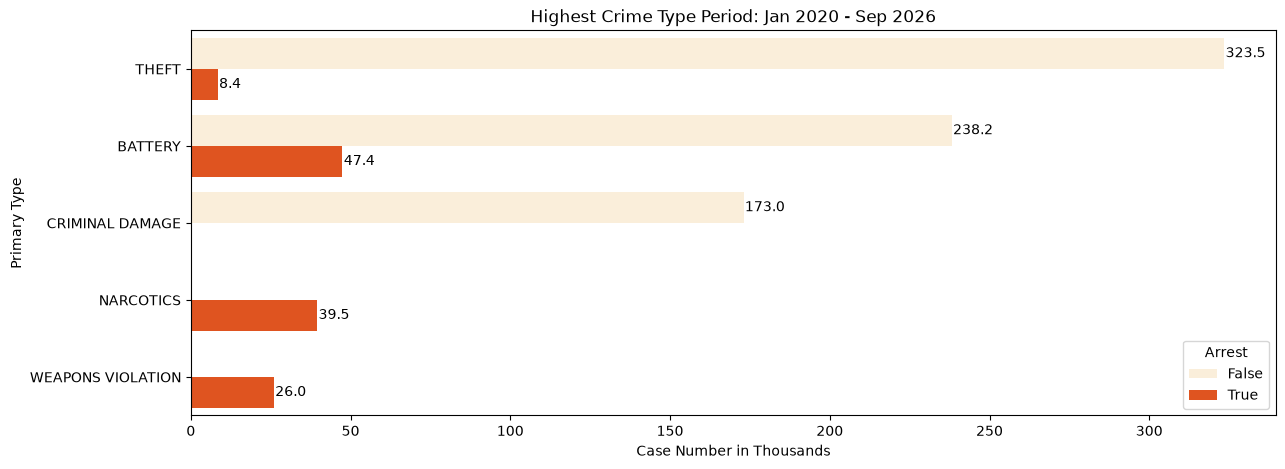

In [40]:
plt.figure(figsize=(14,5))

ax = sns.barplot(data=df_Crime, y='Primary Type', x='Case Count (k)', estimator='sum', hue='Arrest', errorbar=None, palette=color_pallete)
ax.set_title('Highest Crime Type Period: Jan 2020 - Sep 2026')
ax.set_xlabel('Case Number in Thousands')

# Bar Annotation
for container in ax.containers:
  ax.bar_label(container, fmt="%.1f", label_type="edge", color='black', padding=1)

In [41]:
# Total Crimes from each location
df_address = df[['Latitude', 'Longitude']].value_counts().reset_index()
df_address = df_address.rename(columns={'count':'Total Crime'})
df_address.head()

,Latitude,Longitude,Total Crime
0,41.883500,-87.627877,1723
1,41.754593,-87.741529,1501
2,41.788987,-87.741480,1489
3,41.976290,-87.905227,1455
4,41.963071,-87.655984,1146


In [42]:
# Count how many crimes happened in the same location annualy

for year in df['Year'].unique():
    df_temp = df[df['Year']==year].groupby(['Latitude', 'Longitude'], as_index=False)['Case Number'].count()
    df_temp = df_temp.rename(columns={'Case Number':f'Case_{int(year)}'})
    df_address = df_address.merge(right=df_temp,
                     how='outer',
                     left_on=['Latitude', 'Longitude'],
                     right_on=['Latitude', 'Longitude'])

df_address = df_address.fillna(value=0).sort_values(by='Total Crime', ascending=False)    
df_address.head()

,Latitude,Longitude,Total Crime,Case_2026,Case_2025,Case_2024,Case_2023,Case_2022,Case_2021,Case_2020
220077,41.883500,-87.627877,1723,73.0,193.0,334.0,464.0,285.0,163.0,211.0
76428,41.754593,-87.741529,1501,171.0,315.0,341.0,232.0,178.0,137.0,127.0
125674,41.788987,-87.741480,1489,171.0,249.0,286.0,310.0,225.0,163.0,85.0
343147,41.976290,-87.905227,1455,183.0,187.0,164.0,239.0,315.0,212.0,155.0
328542,41.963071,-87.655984,1146,170.0,294.0,261.0,191.0,116.0,49.0,65.0


In [43]:
# Adjust acceptable total crime happened in a year 
annual_crime_threshold = 12
total_thres = 12 * df['Year'].nunique()

df_Crime_Ann = df_address[ (df_address['Total Crime']>total_thres) | (df_address['Case_2026']>total_thres) ]
print (df_Crime_Ann.shape, '\n')
df_Crime_Ann.head()

(1217, 10) 



,Latitude,Longitude,Total Crime,Case_2026,Case_2025,Case_2024,Case_2023,Case_2022,Case_2021,Case_2020
220077,41.883500,-87.627877,1723,73.0,193.0,334.0,464.0,285.0,163.0,211.0
76428,41.754593,-87.741529,1501,171.0,315.0,341.0,232.0,178.0,137.0,127.0
125674,41.788987,-87.741480,1489,171.0,249.0,286.0,310.0,225.0,163.0,85.0
343147,41.976290,-87.905227,1455,183.0,187.0,164.0,239.0,315.0,212.0,155.0
328542,41.963071,-87.655984,1146,170.0,294.0,261.0,191.0,116.0,49.0,65.0


In [44]:
import folium
import branca.colormap as cm

In [45]:
chicago_loc = [41.87977907670405, -87.60833570054515]
plt.figure(figsize=(15,4))

ChicagoMap = folium.Map(
    location=chicago_loc,
    zoom_start=11
)

# Color scale
colormap = cm.linear.Dark2_08.scale(
    df_Crime_Ann['Total Crime'].min(),
    df_Crime_Ann['Total Crime'].max()
)

for _, row in df_Crime_Ann.iterrows():
    folium.CircleMarker(
        location=[row['Latitude'], row['Longitude']],
        radius=4,
        color=colormap(row['Total Crime']),
        fill=True,
        fill_color=colormap(row['Total Crime']),
        fill_opacity=0.7,
        popup=f"Total Crime Recorded: {row['Total Crime']}"
    ).add_to(ChicagoMap)

colormap.caption = "Total Crime"
colormap.add_to(ChicagoMap)

ChicagoMap

<Figure size 1500x400 with 0 Axes>

In [46]:
# Source: https://datahub.cmap.illinois.gov/maps/CMAPGIS::community-data-snapshots-historical-data-2015-2026/about
# Data Dictionary: https://cmapgis.maps.arcgis.com/home/item.html?id=631f66168dc54a75a39979def8da4f67#overview

df_Comm_Pop_2024 = pd.read_csv(path + 'Chicago_CommunityDataSnapshots_Historical_2026.csv',
                              usecols=['GEOID', 'TOT_POP'])

df_Comm_Pop_2024 = df_Comm_Pop_2024.rename(columns={'GEOID':'Community Area', 'TOT_POP': 'Population_2024'})
df_Comm_Pop_2024 = df_Comm_Pop_2024.astype({
    'Community Area' : 'int', 'Population_2024' : 'int'
}).sort_values(by='Community Area').reset_index(drop=True)
df_Comm_Pop_2024.head()

,Community Area,Population_2024
0,1,54173
1,2,78373
2,3,56344
3,4,41651
4,5,36014


In [47]:
df_Comm_Pop_2024['Population_2024'].describe()

count        77.00000
mean      35209.25974
std       23670.96445
min        2304.00000
25%       18417.00000
50%       29941.00000
75%       43779.00000
max      107331.00000
Name: Population_2024, dtype: float64

In [48]:
# Total Crimes from each Comm Area
df_Comm = df[['Community Area']].value_counts().reset_index()
df_Comm = df_Comm.rename(columns={'count':'Total Crime'}).sort_values(by='Community Area').reset_index(drop=True)
df_Comm = df_Comm.merge(right=df_Comm_Pop_2024,how='left',
                        left_on='Community Area', right_on='Community Area')

# Count how many crimes happened each Comm Area annualy

for year in df['Year'].unique():
    df_temp = df[df['Year']==year].groupby(['Community Area'], as_index=False)['Case Number'].count()
    df_temp = df_temp.rename(columns={'Case Number':f'Case_{int(year)}'})
    df_Comm = df_Comm.merge(right=df_temp,how='outer',
                     left_on='Community Area', right_on='Community Area')

df_Comm = df_Comm.fillna(value=0).sort_values(by='Community Area').reset_index(drop=True)
df_Comm.head()

,Community Area,Total Crime,Population_2024,Case_2026,Case_2025,Case_2024,Case_2023,Case_2022,Case_2021,Case_2020
0,1.0,25849,54173,2551,3770,4356,4652,4063,3392,3065
1,2.0,23340,78373,2337,3271,3781,4031,3980,3021,2919
2,3.0,26340,56344,3167,4170,4505,4613,3884,3228,2773
3,4.0,13047,41651,1393,1910,2035,2218,2026,1704,1761
4,5.0,8555,36014,921,1250,1384,1498,1382,1029,1091


In [49]:
# Crime per 10.000 population

for col in range(3,10):
    df_Comm.iloc[:,col] = round ( df_Comm.iloc[:,col] / df_Comm.iloc[:,2] * 10000 , 0).astype('int')

df_Comm.head() 

,Community Area,Total Crime,Population_2024,Case_2026,Case_2025,Case_2024,Case_2023,Case_2022,Case_2021,Case_2020
0,1.0,25849,54173,471,696,804,859,750,626,566
1,2.0,23340,78373,298,417,482,514,508,385,372
2,3.0,26340,56344,562,740,800,819,689,573,492
3,4.0,13047,41651,334,459,489,533,486,409,423
4,5.0,8555,36014,256,347,384,416,384,286,303


In [50]:
Dict_Crime_Comm = {
    'Year' : [],
    'Comm Area' : [],
    'Case per 10k' : []
}

df_Comm_Crime = pd.DataFrame(columns=['Year', 'Comm Area', 'Case per 10k'], index=None)

for col in range(3,10):
    top_5 = df_Comm.iloc[:,col].sort_values(ascending=False).head()
    Dict_Crime_Comm['Year'].extend( [df_Comm.columns[col][-4:] ]*5 )
    Dict_Crime_Comm['Comm Area'].extend( top_5.index )
    Dict_Crime_Comm['Case per 10k'].extend( top_5.values )

df_Comm_Crime = pd.DataFrame(Dict_Crime_Comm).sort_values(by=['Year','Case per 10k'], ascending=[True,False])
df_Comm_Crime

,Year,Comm Area,Case per 10k
30,2020,25,3103
31,2020,36,2726
32,2020,67,2079
33,2020,28,1973
34,2020,68,1925
25,2021,25,2883
26,2021,36,2398
27,2021,67,2056
28,2021,28,1971
29,2021,68,1943


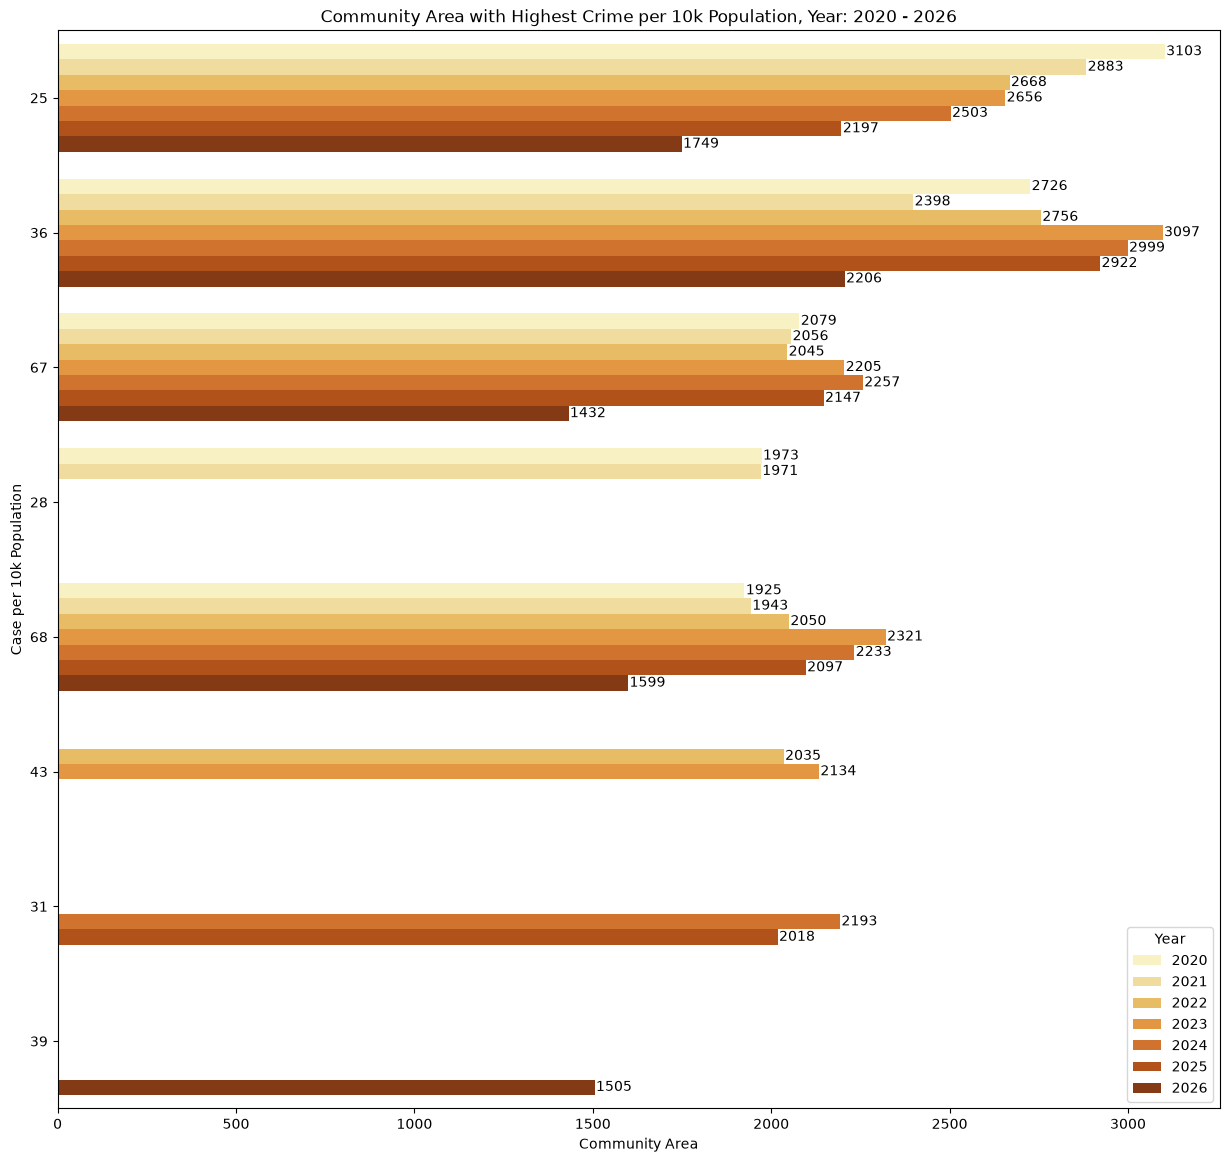

In [51]:
plt.figure(figsize=(15,14))

ax = sns.barplot(data=df_Comm_Crime, y=df_Comm_Crime['Comm Area'].astype('str'), x='Case per 10k', estimator='sum', hue='Year', errorbar=None, palette='YlOrBr')
ax.set_title('Community Area with Highest Crime per 10k Population, Year: 2020 - 2026')
ax.set_ylabel('Case per 10k Population')
ax.set_xlabel('Community Area')

# Bar Annotation
for container in ax.containers:
  ax.bar_label(container, fmt="%.f", label_type="edge", color='black', padding=1)

Area 28 and 43 did not recorded any crime for the past 3 years.\
Area 31 and 39 recorded crime recently.\
Area 25, 36, 67, 68 generally recorded crime decreasing by year compared to previous year (2026 until Sep).

### Crime Mitigation

Can we try to reduce the number of crimes, by placing Law Enforcers, or patrols by the center of repeated crime areas?\
In this analysis, Unsupervised Machine Learning Model will be used to define crime clusters and the ideal central location. 

In [52]:
# Unsupervised model
from sklearn.cluster import AgglomerativeClustering

# Metric evaluation
from sklearn.metrics import silhouette_score

In [53]:
# Take data from 2025 and 2026
df_Crime_2Y = df_Crime_Ann[['Latitude',	'Longitude', 'Case_2026', 'Case_2025']]
df_Crime_2Y = df_Crime_2Y.dropna()
df_Crime_2Y.shape

(1217, 4)

In [54]:
# Precomputed haversince distance
from sklearn.metrics.pairwise import haversine_distances

coords = np.radians(df_Crime_2Y[['Latitude', 'Longitude']])
earth_radius_km = 6371
X_havers = haversine_distances(coords) * earth_radius_km

In [55]:
# Searching for best clusters by using Agglomerative Clustering algorithm

n_size = []
val_cluster = []
val_sill = []

# Find best cluster, based on Silhouette
for size in np.arange(7, 3, -0.5):        
    
    n_size.append(size)

    mod_Agglo = AgglomerativeClustering(
        metric='precomputed',
        linkage='complete',
        distance_threshold=size,   # With precomputed haversine, distance_threshold is in kilometers
        n_clusters=None
    )

    y_pred = mod_Agglo.fit_predict(X_havers)

    if max(np.unique(y_pred))>0: 
        val_cluster.append( (np.unique(y_pred)>=0).sum() )
    else:
        val_cluster.append(1) #Only label 0 and outliers

    val_sill.append( silhouette_score(X=X_havers, labels=y_pred) )

df_Model = pd.DataFrame(
    {'n_size':n_size,
     'n_cluster':val_cluster,
     'silhouette':val_sill}
)

# High silhouette
df_Model.sort_values(by=['silhouette'], ascending=[False]).head()

,n_size,n_cluster,silhouette
1,6.5,30,0.365854
4,5.0,44,0.365147
3,5.5,40,0.364960
6,4.0,58,0.363404
0,7.0,28,0.363246


<Axes: xlabel='n_cluster', ylabel='silhouette'>

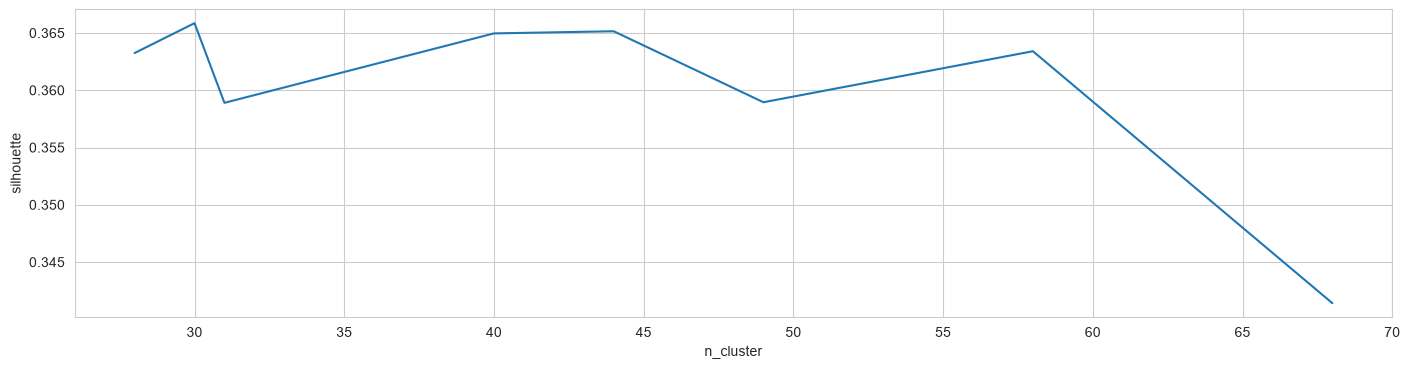

In [56]:
plt.figure(figsize=(17,4))
sns.set_style('whitegrid')

sns.lineplot(data=df_Model,x='n_cluster', y='silhouette',errorbar=None)

Based on the model silhouettte score, it is acceptable if the data clustered for each 5.0 km.\
Driving speed in a heavy traffic city is about 20-30 km/hour, which around  5 - 7.5 km per 15 minutes.\
Consider we want to mitigate crimes; or reaching the crime scene as soon as possible, 5 km in radius is acceptable.

In [57]:
# Remodel; 
X_rad = np.radians(df_Crime_2Y[['Latitude', 'Longitude']])

mod_Agglo = AgglomerativeClustering(
        metric='precomputed',
        linkage='complete',
        distance_threshold=5,
        n_clusters=None
    )
    
df_Crime_2Y['Cluster'] = mod_Agglo.fit_predict(X_havers)

In [58]:
# Auto Color Map for each clusters
cmap = plt.cm.nipy_spectral
clusters = sorted( df_Crime_2Y['Cluster'].unique() )

color_map = {
    int(c): mcolors.to_hex(cmap(i / len(clusters)))
    for i, c in enumerate(clusters)
}
color_map[-1] = '#000000'  # outlier

In [59]:
# Clustered Map

Clustered = folium.Map(
    location=chicago_loc,
    zoom_start=11
)

for _, row in df_Crime_2Y.iterrows():
    
    clust = int(row['Cluster'])
    cMap = str(color_map[clust])
    
    folium.CircleMarker(
        location=[ row['Latitude'], row['Longitude'] ],
        radius=np.sqrt(row['Case_2026'])/2,
        color=cMap,
        fill=True,
        fill_color=cMap,
        popup=f"Cluster {clust}, Case of 2026 {row['Case_2026']}"
    ).add_to(Clustered)

Clustered

In [60]:
# Find the center of the cluster
from scipy.spatial.distance import cdist

medoids = []

for cluster in df_Crime_2Y['Cluster'].unique():

    if cluster == -1:
        continue

    points = df_Crime_2Y[df_Crime_2Y['Cluster'] == cluster][['Latitude', 'Longitude', 'Cluster']]

    center = points[['Latitude', 'Longitude']].mean()

    distances = cdist(
        points[['Latitude', 'Longitude']],
        [center]
    )

    medoid = points.iloc[distances.argmin()]
    medoids.append(medoid)

df_Center_of_Cluster = pd.DataFrame(medoids)

In [61]:
for _, row in df_Center_of_Cluster.iterrows():
    
    clust = int(row['Cluster'])
    cMap = str(color_map[clust])
    
    folium.Marker(
        location=[ row['Latitude'], row['Longitude'] ],
        color=cMap,
        fill=True,
        fill_color=cMap,
        icon=folium.Icon(
            color='darkblue',
            icon='star',
            ),
        tooltip=f"Center of Cluster {clust}",
    ).add_to(Clustered)

Clustered    

In [62]:
# Save map file
Clustered.save("Clustered_Map.html")

### Conclusion

Although crime is inevitable in metropolitan city, people may think twice to commit a crime when law enforcers are present at the moment. The least we can do, is to minimize the loss or damage that caused by the crimes.